In [140]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import torch.optim as optim
import seaborn as sns
import matplotlib.pyplot as plt
import copy

In [115]:
from sklearn.preprocessing import StandardScaler

In [116]:
torch.manual_seed(42)

In [117]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [118]:

X_test = pd.read_csv('./DATASET/team10/task2/test_data.csv', header=None)
y_test = pd.read_csv('./DATASET/team10/task2/test_label.csv', header=None)
X_train = pd.read_csv('./DATASET/team10/task2/train_data.csv', header=None)
y_train = pd.read_csv('./DATASET/team10/task2/train_label.csv', header=None)
X_val = pd.read_csv('./DATASET/team10/task2/val_data.csv', header=None)
y_val = pd.read_csv('./DATASET/team10/task2/val_label.csv', header=None)

In [119]:
X_train.head()

,0,1,2,3,4,5,6,7,8,9,...,26,27,28,29,30,31,32,33,34,35
0,0.201662,0.074938,0.279889,0.279889,0.279889,0.144135,0.122815,0.038869,0.006019,0.279889,...,0.120875,0.108686,0.054314,0.096351,0.175157,0.165119,0.279889,0.094687,0.058798,0.060291
1,0.007426,0.053569,0.016722,0.025131,0.010005,0.011993,0.001363,0.002149,0.002399,0.206460,...,0.251787,0.204749,0.247614,0.215617,0.188633,0.251787,0.251787,0.169791,0.130121,0.190138
2,0.149188,0.079320,0.123547,0.251921,0.251921,0.115030,0.195939,0.123889,0.089928,0.249956,...,0.251921,0.127847,0.226599,0.091530,0.121140,0.066567,0.106946,0.251921,0.095359,0.174059
3,0.047375,0.110300,0.032591,0.099266,0.260827,0.260827,0.083016,0.076367,0.117907,0.260827,...,0.134726,0.048460,0.049957,0.024819,0.056699,0.260827,0.260827,0.260827,0.080256,0.050339
4,0.176717,0.059392,0.072034,0.275782,0.242316,0.275782,0.275782,0.112434,0.038215,0.046910,...,0.043967,0.101286,0.038297,0.038545,0.074975,0.049102,0.255767,0.275782,0.275782,0.046724


In [120]:
X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape

((2000, 36), (2000, 1), (500, 36), (500, 1), (500, 36), (500, 1))

In [121]:
len(y_train.iloc[:,0].unique())

5

In [122]:
class CustomDataset(Dataset):
  def __init__(self, features, labels):
    # print("INIT features shape:", features.shape)
    # print("INIT labels shape:", labels.shape)
    self.features = torch.tensor(features, dtype= torch.float32)
    self.labels = torch.tensor(labels, dtype= torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self, idx):
    return self.features[idx], self.labels[idx]

In [123]:
# Standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [124]:
# train_dataset = CustomDataset(X_train.values, y_train.values)
# val_dataset = CustomDataset(X_val.values, y_val.values)
# test_dataset = CustomDataset(X_test.values, y_test.values)

train_dataset = CustomDataset(X_train_scaled, y_train.values)
val_dataset = CustomDataset(X_val_scaled, y_val.values)
test_dataset = CustomDataset(X_test_scaled, y_test.values)

In [125]:
len(train_dataset), len(val_dataset), len(test_dataset)

(2000, 500, 500)

In [139]:
train_loader = DataLoader(train_dataset, batch_size = 100,shuffle=True, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size = 100,shuffle=False, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size = 100,shuffle=False, pin_memory=True)

In [127]:
train_loader.dataset.features.shape, train_loader.dataset.labels.shape

(torch.Size([2000, 36]), torch.Size([2000, 1]))

In [128]:
class MyNN(nn.Module):
  def __init__(self, num_features, num_classes):
    super().__init__()

    self.model = nn.Sequential(
        nn.Linear(num_features, 20),
        nn.Tanh(),
        nn.Linear(20,10),
        nn.Tanh(),
        nn.Linear(10, num_classes)
    )

  def forward(self, x):
    return self.model(x)

In [129]:
class MyNN_LN(nn.Module):
  def __init__(self, num_features, num_classes):
    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(num_features, 20),
        nn.Tanh(),
        nn.LayerNorm(20),

        nn.Linear(20,10),
        nn.Tanh(),
        nn.LayerNorm(10),

        nn.Linear(10, num_classes)
    )

  def forward(self, x):
    return self.model(x)

In [130]:
class MyNN_BN(nn.Module):
  def __init__(self, num_features, num_classes):
    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(num_features, 20),
        nn.Tanh(),
        nn.BatchNorm1d(20),

        nn.Linear(20,10),
        nn.Tanh(),
        nn.BatchNorm1d(10),

        nn.Linear(10, num_classes)
    )

  def forward(self, x):
    return self.model(x)

In [131]:
learning_rate = 1e-3
threshold = 1e-5

In [132]:
num_features = X_train.shape[1]
num_classes = len(y_train.iloc[:,0].unique())
torch.manual_seed(42)
model = MyNN(
    num_features = num_features,
    num_classes = num_classes
)
torch.manual_seed(42)
model_LN = MyNN_LN(
    num_features = num_features,
    num_classes = num_classes
)
torch.manual_seed(42)
model_BN = MyNN_BN(
    num_features = num_features,
    num_classes = num_classes
)

models = {
    'model' : model,
    'model_LN' : model_LN,
    'model_BN' : model_BN
}

In [133]:
results = {}

In [142]:
criterion = nn.CrossEntropyLoss()

num_epochs = {}
train_loss_history = {}
val_loss_history = {}
trained_models = {}

for model_name, model in models.items():
  print(f"----------------------------- Model: {model_name} -----------------------------")
  model.to(device)
  optimizer = optim.Adam(model.parameters(), lr = learning_rate)

  prev_loss = float('inf')
  best_val_loss = float('inf')
  best_model_weights = None
  
  epoch = 0
  epoch_train_losses = []
  epoch_val_losses = []
  while epoch < 10000:
    
    model.train()
    total_epoch_train_loss = 0.0

    for batch_features, batch_labels in train_loader:
      batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
      batch_labels = batch_labels.squeeze()

      optimizer.zero_grad()
      outputs = model(batch_features)
      loss = criterion(outputs, batch_labels)
      loss.backward()
      optimizer.step()

      total_epoch_train_loss += loss.item() * batch_features.size(0)

    avg_train_loss = total_epoch_train_loss / len(train_dataset)
    epoch_train_losses.append(avg_train_loss)
        
    # ----------------------------------------------
    # VALIDATION
    # ----------------------------------------------
    
    model.eval()
    total_val_loss = 0.0
    with torch.no_grad():
      for val_features, val_labels in val_loader:
        val_features, val_labels = val_features.to(device), val_labels.to(device)
        val_labels = val_labels.squeeze()
        
        val_outputs = model(val_features)
        val_loss = criterion(val_outputs, val_labels)
        total_val_loss += val_loss.item() * val_features.size(0)
    
    avg_val_loss = total_val_loss / len(val_dataset)
    epoch_val_losses.append(avg_val_loss)
    
    
    # ----------------------------
    # FINE TUNE UPDATE
    # ----------------------------
    if avg_val_loss < best_val_loss:
      best_val_loss = avg_val_loss
      best_model_weights = copy.deepcopy(model.state_dict())
    
    epoch += 1
    
    # -----------------------------
    # EARLY STOPPING
    # -----------------------------
    
    if abs(prev_loss - avg_train_loss) < threshold:
      print("Converged")
      break
    prev_loss = avg_train_loss
    print(f"Epoch: {epoch}, Train Loss: {avg_train_loss}, Val Loss: {avg_val_loss}")

  model.load_state_dict(best_model_weights)
  
  num_epochs[model_name] = epoch
  train_loss_history[model_name] = epoch_train_losses
  val_loss_history[model_name] = epoch_val_losses
  trained_models[model_name] = model

----------------------------- Model: model -----------------------------
Epoch: 1, Train Loss: 0.8814941436052323, Val Loss: 1.4706634044647218
Epoch: 2, Train Loss: 0.8748081952333451, Val Loss: 1.4654119491577149
Epoch: 3, Train Loss: 0.8736205846071243, Val Loss: 1.4739323377609252
Epoch: 4, Train Loss: 0.8703731924295426, Val Loss: 1.4749018907546998
Epoch: 5, Train Loss: 0.8695960372686387, Val Loss: 1.4786393880844115
Epoch: 6, Train Loss: 0.8671645790338516, Val Loss: 1.4820287942886352
Epoch: 7, Train Loss: 0.8654409050941467, Val Loss: 1.482305645942688
Epoch: 8, Train Loss: 0.8630989581346512, Val Loss: 1.4890387058258057
Epoch: 9, Train Loss: 0.8614289313554764, Val Loss: 1.4915942907333375
Epoch: 10, Train Loss: 0.8605365544557572, Val Loss: 1.4929912567138672
Epoch: 11, Train Loss: 0.8582025051116944, Val Loss: 1.5000174045562744
Epoch: 12, Train Loss: 0.8570887207984924, Val Loss: 1.5022483110427856
Epoch: 13, Train Loss: 0.8551130056381225, Val Loss: 1.504930567741394
Ep

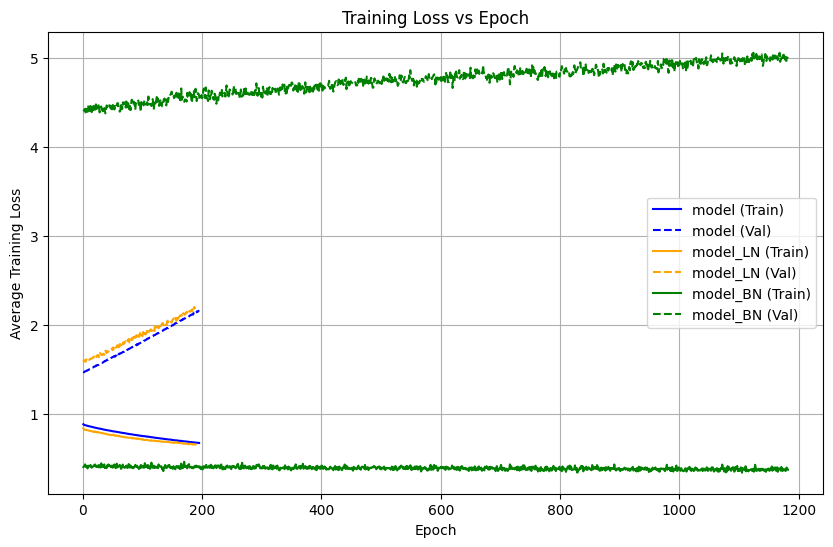

In [144]:
plt.figure(figsize=(10,6))

colors = {
  'model' : 'blue',
  'model_LN' : 'orange',
  'model_BN' : 'green'
}

for model_name in train_loss_history.keys():
  color = colors[model_name]
  # Train Loss
  plt.plot(
    range(1, len(train_loss_history[model_name]) + 1),
    train_loss_history[model_name],
    label=f"{model_name} (Train)",
    color=color,
    linestyle='-'
  )
  
  # Val Loss
  plt.plot(
    range(1, len(val_loss_history[model_name]) + 1),
    val_loss_history[model_name],
    label=f"{model_name} (Val)",
    color=color,
    linestyle='--'
  )
plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.title("Training Loss vs Epoch")
plt.legend()
plt.grid(True)
plt.show()

In [145]:
# %%
from sklearn.metrics import confusion_matrix

def get_preds(model, loader):
  model.eval()
  all_preds = []
  all_labels = []
  with torch.no_grad():
    for batch_features, batch_labels in loader:
      batch_features, batch_labels = batch_features.to(device), batch_labels.squeeze().to(device)
      outputs = model(batch_features)

      _, preds = torch.max(outputs, 1)

      all_preds.extend(preds.cpu().numpy())
      all_labels.extend(batch_labels.cpu().numpy())

  return all_preds, all_labels

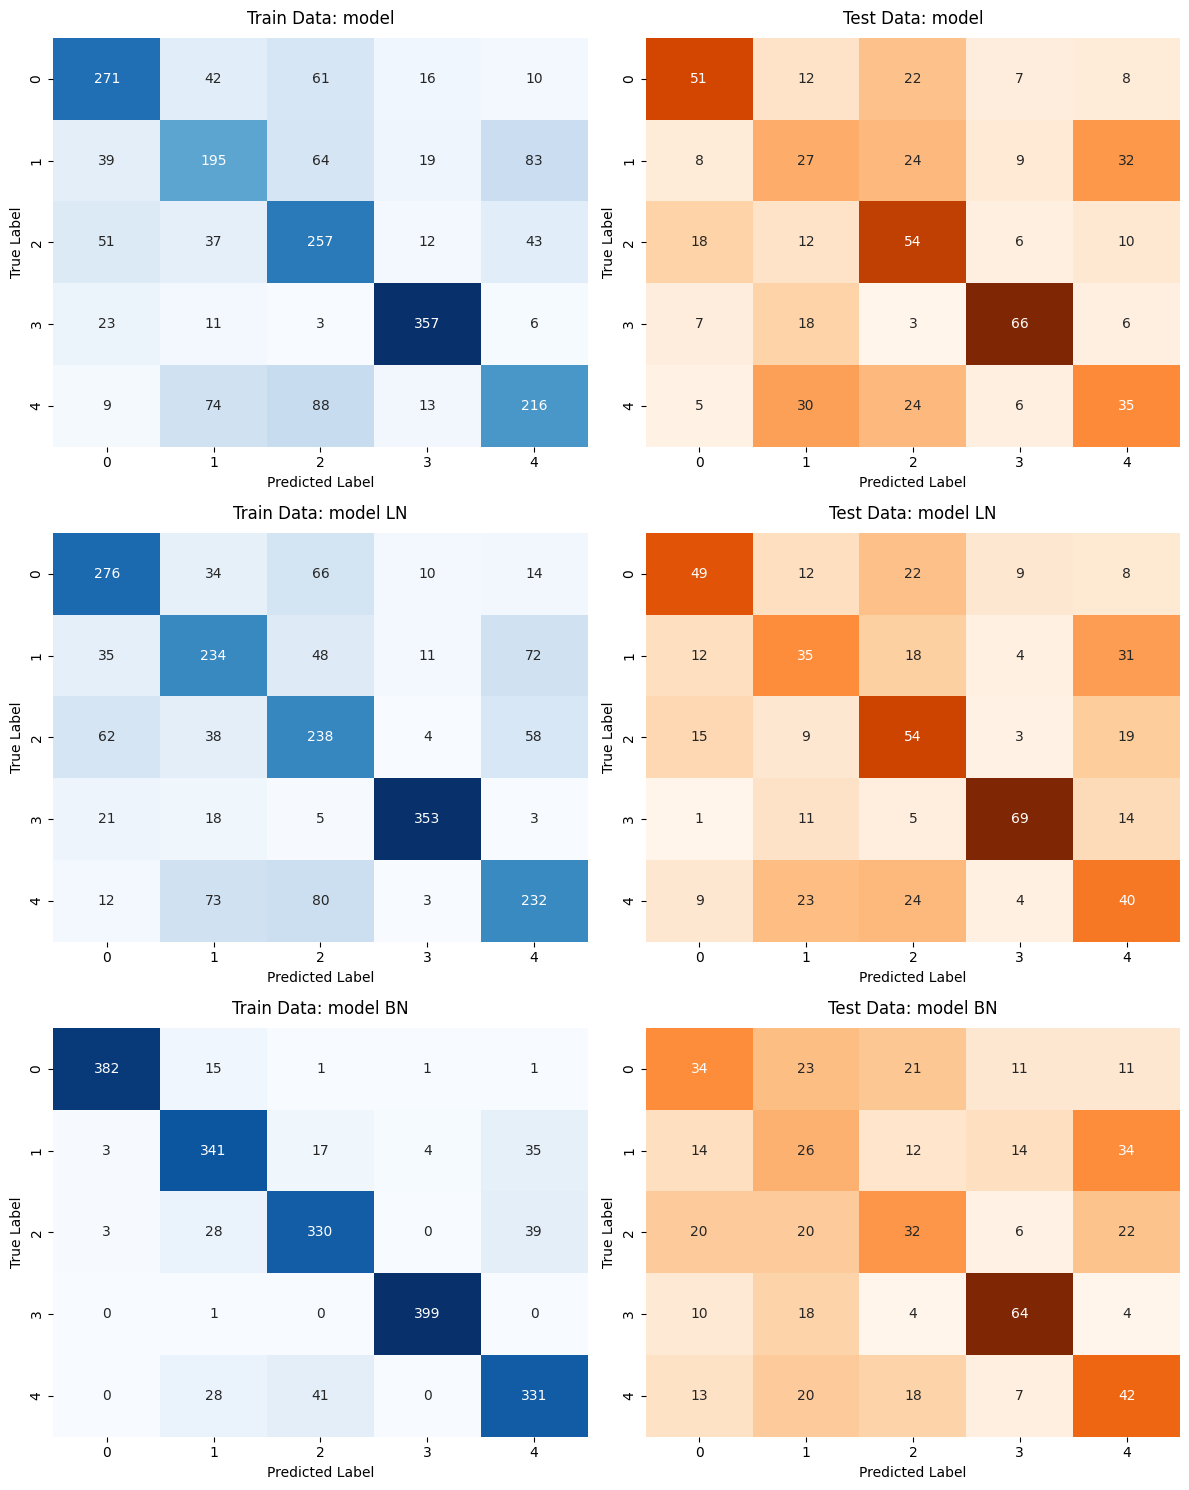

In [146]:
fig, axes = plt.subplots(len(trained_models), 2, figsize=(12, 5 * len(trained_models)))

for row_idx, (model_name, model) in enumerate(trained_models.items()):
    
    splits = [
        ("Train", train_loader, "Blues", 0),
        ("Test",  test_loader,  "Oranges", 1)
    ]
    
    for split_name, loader, cmap, col_idx in splits:
        preds, labels = get_preds(model, loader)
        cm = confusion_matrix(labels, preds)
        
        ax = axes[row_idx, col_idx]
        
        sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax, cbar=False)
        
        ax.set_title(f"{split_name} Data: {model_name.replace('_', ' ')}", fontsize=12, pad=10)
        ax.set_xlabel('Predicted Label')
        ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()